# Demo 2: Open-Vocabulary Detection — Grounding DINO

**Model:** `IDEA-Research/grounding-dino-base`  
**Task:** Detect any object described by free-form text (no fixed class list)

---
**Flow:**
1. Capture image from webcam (or load from file)
2. Load Grounding DINO model
3. Enter text query → detect objects and visualize results


In [ ]:

# ── Imports ──────────────────────────────────────────────────────────────────
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '2'
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import cv2

import warnings
warnings.filterwarnings('ignore')

## Step 1: Capture Image

In [ ]:
# # ── Option A: Webcam capture ──────────────────────────────────────────────────
# # Press 'SPACE' or 'Enter' to capture, 'q' to quit.

# def capture_from_webcam():
#     cap = cv2.VideoCapture(0)
#     if not cap.isOpened():
#         print("Webcam not found. Use Option B (load from file).")
#         return None

#     print("Webcam window opened. Press [SPACE] or [Enter] to capture, [q] to quit.")
#     captured_frame = None
#     while True:
#         ret, frame = cap.read()
#         if not ret:
#             break
#         cv2.imshow("Webcam — Press SPACE to capture, Q to quit", frame)
#         key = cv2.waitKey(1) & 0xFF
#         if key in (ord(' '), 13):   # SPACE or Enter
#             captured_frame = frame
#             print("Captured!")
#             break
#         elif key == ord('q'):
#             break

#     cap.release()
#     cv2.destroyAllWindows()

#     if captured_frame is not None:
#         return Image.fromarray(cv2.cvtColor(captured_frame, cv2.COLOR_BGR2RGB))
#     return None

# image = capture_from_webcam()

# if image:
#     plt.figure(figsize=(8, 6))
#     plt.imshow(image)
#     plt.axis('off')
#     plt.title(f"Captured image  ({image.width} x {image.height})")
#     plt.show()

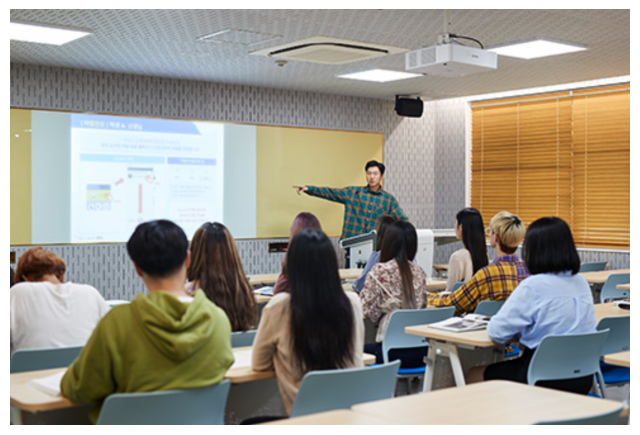

In [2]:
# ──  Load from file ──────────────────────────────────────────────────
IMAGE_PATH = "sample.png"
image = Image.open(IMAGE_PATH).convert("RGB")
plt.figure(figsize=(8, 6))
plt.imshow(image); plt.axis('off'); plt.show()

## Step 2: Load Grounding DINO Model

In [3]:
from models.dino_model import GroundingDINODetector
from utils.visualization import draw_boxes_on_image

dino = GroundingDINODetector()
dino.load()   # downloads model on first run (~340 MB)

/home/nohkw/anaconda3/envs/deeplearning/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Grounding DINO] Loading IDEA-Research/grounding-dino-base on cuda ...
[Grounding DINO] Model loaded.


## Step 3: Detect Objects with a Text Query

Enter the objects you want to detect **separated by periods**.  
Example: `"a person. a face. a laptop."`

> Try changing only the query on the same image for an effective demo!


/home/nohkw/anaconda3/envs/deeplearning/lib/python3.11/site-packages/transformers/models/grounding_dino/processing_grounding_dino.py:94: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


Detected 2 object(s)
  • a ppt slide           score=0.347  box=[0, 177, 709, 443]
  • a ppt slide           score=0.304  box=[107, 194, 408, 436]


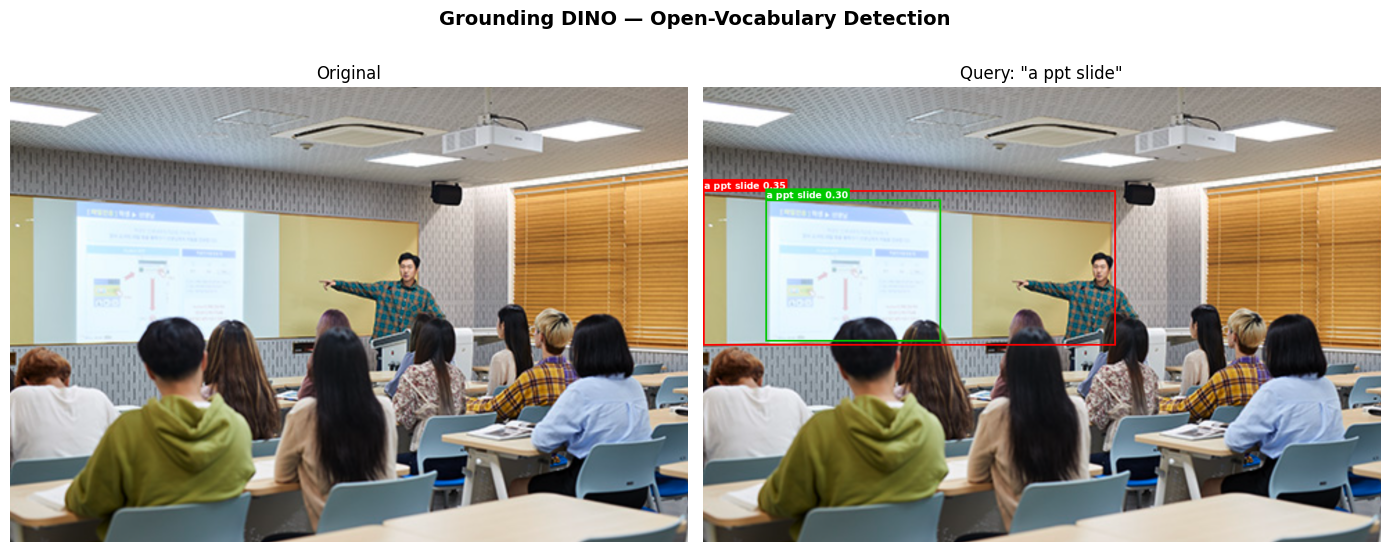

: 

In [ ]:
from utils.visualization import draw_boxes_on_image

# ─── Edit here ───────────────────────────────────────────────────────────────
TEXT_QUERY    = "a ppt slide"
BOX_THRESHOLD = 0.3    # detections below this score are discarded (lower = more detections)
TEXT_THRESHOLD = 0.25
# ─────────────────────────────────────────────────────────────────────────────

boxes, scores, labels = dino.predict(
    image, TEXT_QUERY,
    box_threshold=BOX_THRESHOLD,
    text_threshold=TEXT_THRESHOLD,
)

print(f"Detected {len(boxes)} object(s)")
for label, score, box in zip(labels, scores, boxes):
    print(f"  • {label:<20s}  score={score:.3f}  box={[round(v) for v in box]}")

# Visualize
if boxes:
    result = draw_boxes_on_image(image, boxes, scores, labels)
else:
    result = image
    print("No objects detected — try lowering the threshold or changing the query.")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image);  axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(result); axes[1].set_title(f'Query: "{TEXT_QUERY}"'); axes[1].axis('off')
plt.suptitle("Grounding DINO — Open-Vocabulary Detection", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Step 4: Compare Multiple Queries

Run several queries on the same image side by side.


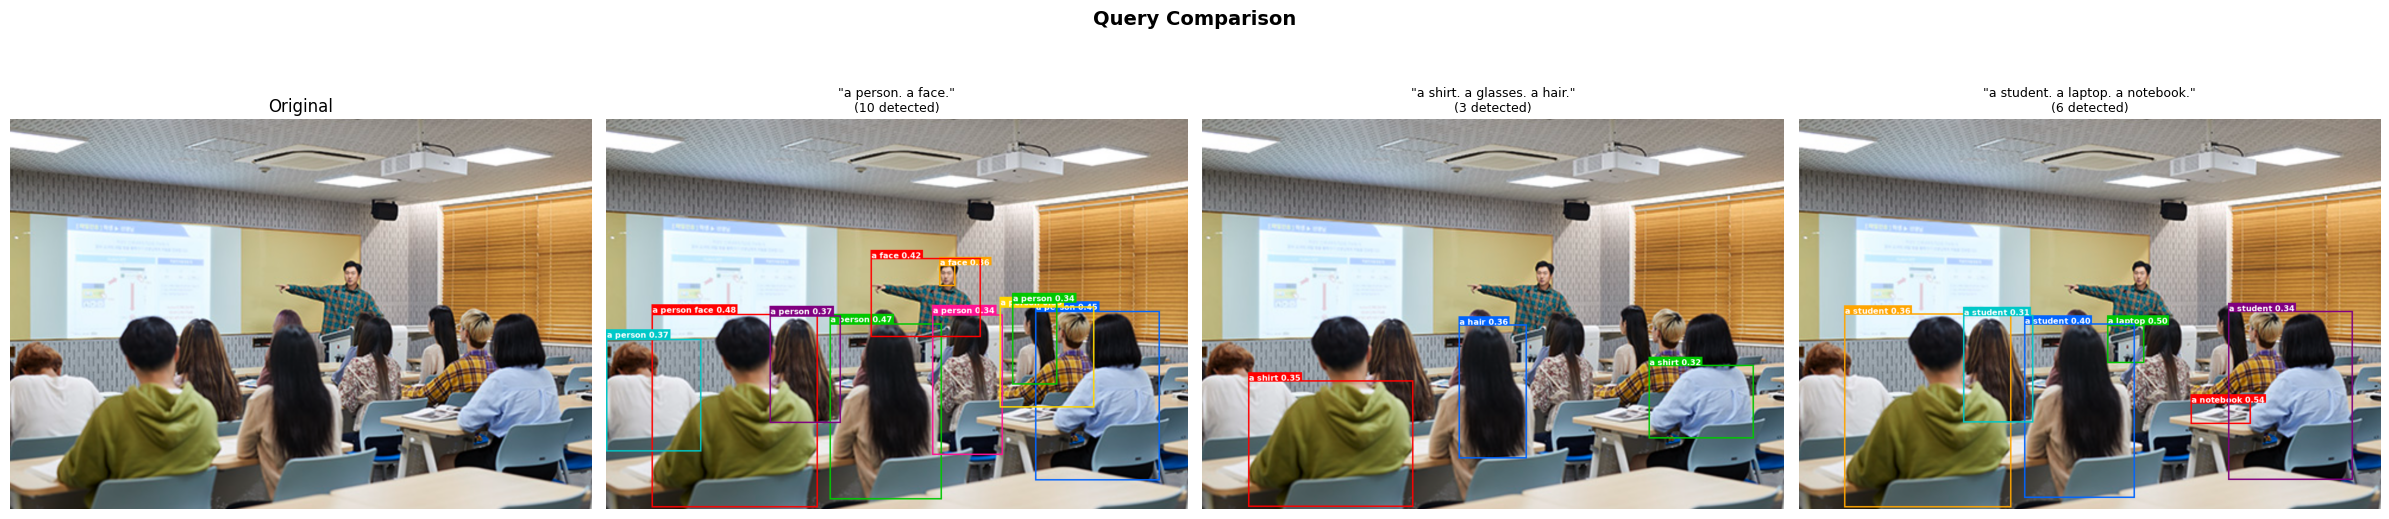

In [ ]:
# ─── List of queries to compare ─────────────────────────────────────────────
# QUERIES = [
#     "a person. a face.",
#     "a shirt. a glasses. a hair.",
#     "a student. a laptop. a notebook.",
# ]
# # ─────────────────────────────────────────────────────────────────────────────

# fig, axes = plt.subplots(1, len(QUERIES) + 1, figsize=(6 * (len(QUERIES) + 1), 6))
# axes[0].imshow(image); axes[0].set_title("Original"); axes[0].axis('off')

# for i, query in enumerate(QUERIES, start=1):
#     boxes_q, scores_q, labels_q = dino.predict(image, query,
#                                                 box_threshold=BOX_THRESHOLD,
#                                                 text_threshold=TEXT_THRESHOLD)
#     result_q = draw_boxes_on_image(image, boxes_q, scores_q, labels_q) if boxes_q else image
#     axes[i].imshow(result_q)
#     axes[i].set_title(f'"{query}"\n({len(boxes_q)} detected)', fontsize=9)
#     axes[i].axis('off')

# plt.suptitle("Query Comparison", fontsize=14, fontweight='bold')
# plt.tight_layout()
# plt.show()